# Train U-Net on a Kaggle dataset

Segmentation training with **segmentation-models-pytorch** and an
**Albumentations** pipeline (brightness, shadows, zoom in/out, flips, blur, noise).

**Before you run:** attach your dataset via **Add Input → Datasets**, then
update `IMAGES_DIR` and `MASKS_DIR` in the config cell.

Enable GPU: Settings → Accelerator → GPU (T4 x2 or P100).

## 1. Install packages

`torch`, `cv2`, `tqdm` are already on Kaggle.

In [2]:
# !pip install -q segmentation-models-pytorch albumentations

## 2. Explore the input directory

In [3]:
# import os
# for root, dirs, files in os.walk("/kaggle/input"):
#     depth = root.replace("/kaggle/input", "").count(os.sep)
#     if depth > 3: continue
#     print("  " * depth + os.path.basename(root) + "/")
#     if depth < 3:
#         for f in files[:5]:
#             print("  " * (depth + 1) + f)
#         if len(files) > 5:
#             print("  " * (depth + 1) + f"... ({len(files)} files total)")

## 3. Config

Images and masks must share filenames. `num_classes=1` → binary, else multi-class.

In [4]:
# ---- EDIT THESE ---------------------------------------------------
IMAGES_DIR   = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\clean_unet_dataset\images"
MASKS_DIR    = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\clean_unet_dataset\masks"

NUM_CLASSES  = 1        # 1 = binary segmentation
IMG_SIZE     = 256
BATCH_SIZE   = 16
EPOCHS       = 1
LR           = 1e-4
TRAIN_RATIO  = 0.8
ENCODER      = "resnet34"
ENCODER_W    = "imagenet"

SAVE_BEST    = r".\unet_best.pth"
SAVE_FINAL   = r".\unet_final.pth"
# -------------------------------------------------------------------

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


## 4. Dataset class

In [5]:
from pathlib import Path
import cv2, numpy as np
from torch.utils.data import Dataset

class SegmentationDataset(Dataset):
    IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

    def __init__(self, images_dir, masks_dir, transform=None):
        self.images_dir = Path(images_dir)
        self.masks_dir  = Path(masks_dir)
        self.transform  = transform
        self.images = sorted(f for f in self.images_dir.iterdir()
                             if f.suffix.lower() in self.IMG_EXTS)
        if not self.images:
            raise RuntimeError(f"No images in {self.images_dir}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        mask_path = self.masks_dir / (img_path.stem + ".png")

        image = cv2.imread(str(img_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise FileNotFoundError(f"missing mask for {img_path.name}")
        mask = (mask > 127).astype(np.float32)

        if self.transform:
            out = self.transform(image=image, mask=mask)
            image, mask = out["image"], out["mask"]

        if mask.ndim == 2:
            mask = mask.unsqueeze(0)
        return image, mask

## 5. Augmentation pipeline

Brightness, shadows, zoom in/out (`Affine(scale=…)`), flips, blur, noise, erasing.

In [6]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

def train_transform(size=IMG_SIZE):
    return A.Compose([
        A.Resize(size, size),

        # zoom in/out + slight rotate/translate
        A.Affine(scale=(0.7, 1.3), translate_percent=(-0.1, 0.1),
                 rotate=(-15, 15), p=0.7),

        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),

        # brightness / colour
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
        A.HueSaturationValue(hue_shift_limit=15, sat_shift_limit=25,
                             val_shift_limit=20, p=0.5),
        A.CLAHE(clip_limit=2.0, p=0.2),

        # shadows & lighting
        A.RandomShadow(shadow_roi=(0, 0.5, 1, 1), p=0.4),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 0.5), p=0.15),
        A.RandomFog(p=0.1),

        # blur / noise
        A.OneOf([
            A.GaussianBlur(blur_limit=(3, 7), p=1.0),
            A.MotionBlur(blur_limit=(3, 7), p=1.0),
        ], p=0.3),
        A.GaussNoise(p=0.3),

        A.CoarseDropout(p=0.3),

        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

def val_transform(size=IMG_SIZE):
    return A.Compose([
        A.Resize(size, size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\albumentations\augmentations\pixel\transforms.py:39: UserWarning: A NumPy version >=2.0.0 and <2.8.0 is required for this version of SciPy (detected version 1.26.4)
  from scipy import special


## 6. Train / val split + loaders

In [7]:
import random
from torch.utils.data import DataLoader, Subset

ds_train_view = SegmentationDataset(IMAGES_DIR, MASKS_DIR, train_transform())
ds_val_view   = SegmentationDataset(IMAGES_DIR, MASKS_DIR, val_transform())

n = len(ds_train_view)
idx = list(range(n)); random.Random(42).shuffle(idx)
cut = int(n * TRAIN_RATIO)

train_set = Subset(ds_train_view, idx[:cut])
val_set   = Subset(ds_val_view,   idx[cut:])
print(f"train: {len(train_set)} | val: {len(val_set)}")

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

train: 84744 | val: 21187


## 7. Preview a few augmented samples (sanity check)

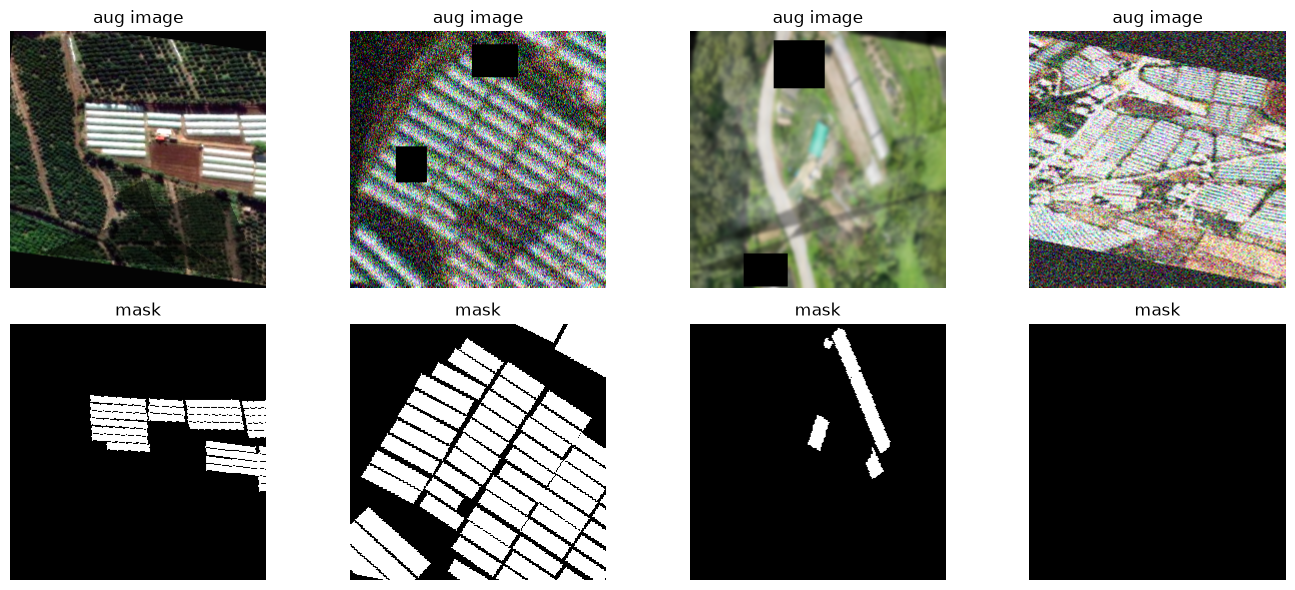

In [8]:
import matplotlib.pyplot as plt
import numpy as np

def denorm(t):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img = t.permute(1, 2, 0).numpy() * std + mean
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i in range(4):
    img, mask = train_set[i]
    axes[0, i].imshow(denorm(img)); axes[0, i].set_title("aug image"); axes[0, i].axis("off")
    axes[1, i].imshow(mask.squeeze(), cmap="gray"); axes[1, i].set_title("mask"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

## 8. Build U-Net

In [9]:
import segmentation_models_pytorch as smp

model = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights=ENCODER_W,
    in_channels=3,
    classes=NUM_CLASSES,
).to(DEVICE)

if NUM_CLASSES == 1:
    criterion = smp.losses.DiceLoss(mode="binary", from_logits=True)
else:
    criterion = smp.losses.DiceLoss(mode="multiclass", from_logits=True)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

## 9. Training loop (saves best checkpoint to `/kaggle/working`)

In [10]:
from tqdm.notebook import tqdm

best_val = float("inf")

for epoch in range(1, EPOCHS + 1):
    # ---- Train ----
    model.train()
    running = 0.0
    for imgs, masks in tqdm(train_loader, desc=f"epoch {epoch}/{EPOCHS} [train]", leave=False):
        imgs  = imgs.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        if NUM_CLASSES > 1:
            masks = masks.squeeze(1).long()

        optimizer.zero_grad()
        preds = model(imgs)
        loss  = criterion(preds, masks)
        loss.backward()
        optimizer.step()
        running += loss.item() * imgs.size(0)
    train_loss = running / len(train_loader.dataset)

    # ---- Val ----
    model.eval()
    running = 0.0
    with torch.no_grad():
        for imgs, masks in tqdm(val_loader, desc=f"epoch {epoch}/{EPOCHS} [val]", leave=False):
            imgs  = imgs.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)
            if NUM_CLASSES > 1:
                masks = masks.squeeze(1).long()
            preds = model(imgs)
            running += criterion(preds, masks).item() * imgs.size(0)
    val_loss = running / len(val_loader.dataset)

    scheduler.step()
    print(f"epoch {epoch:03d} | train {train_loss:.4f} | val {val_loss:.4f}")

    if val_loss < best_val:
        best_val = val_loss
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "encoder": ENCODER,
            "num_classes": NUM_CLASSES,
            "img_size": IMG_SIZE,
        }, SAVE_BEST)
        print(f"   ↳ new best, saved to {SAVE_BEST}")

# Save final too
torch.save(model.state_dict(), SAVE_FINAL)
print(f"\n✅ done. best val: {best_val:.4f}")
print(f"best  → {SAVE_BEST}")
print(f"final → {SAVE_FINAL}")

epoch 1/1 [train]:   0%|          | 0/5297 [00:00<?, ?it/s]

epoch 1/1 [val]:   0%|          | 0/1325 [00:00<?, ?it/s]

epoch 001 | train 0.3245 | val 0.2556
   ↳ new best, saved to .\unet_best.pth

✅ done. best val: 0.2556
best  → .\unet_best.pth
final → .\unet_final.pth


## 10. Preview predictions on val

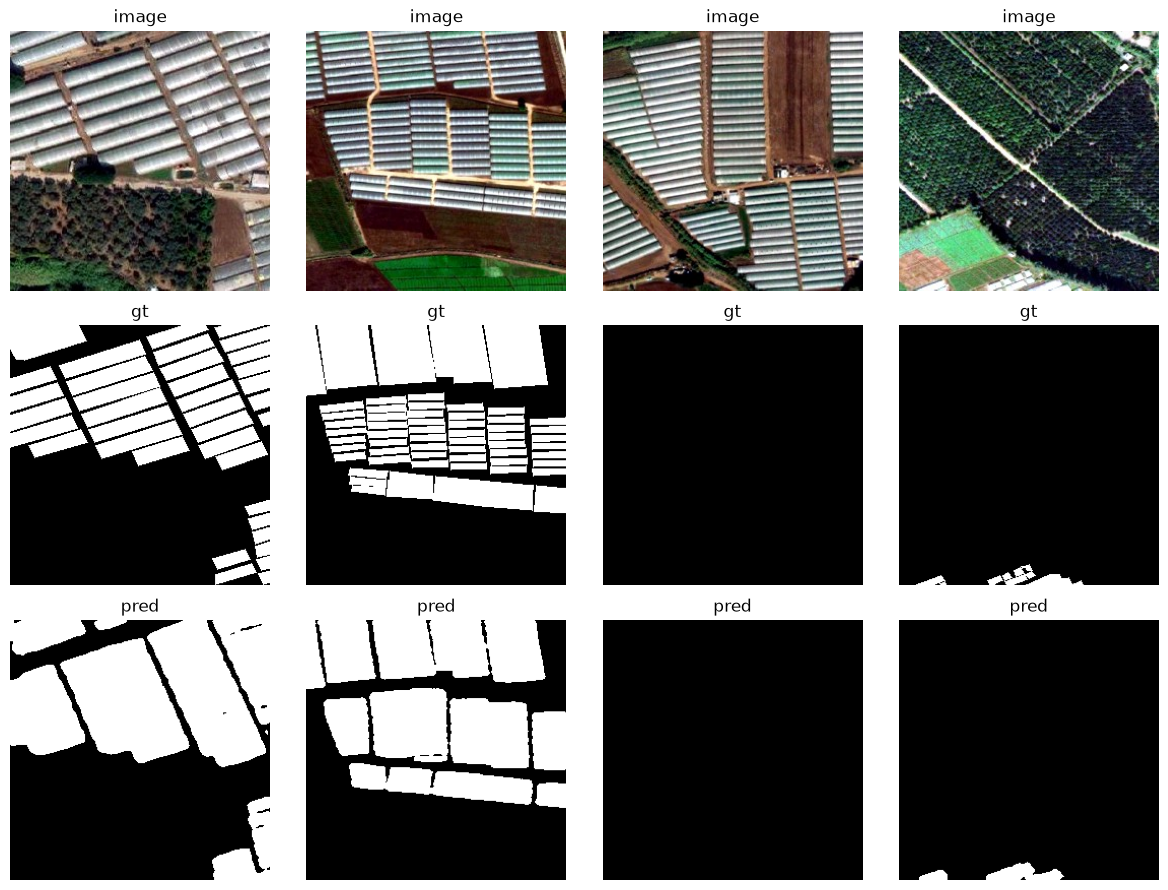

In [11]:
model.eval()
imgs, masks = next(iter(val_loader))
with torch.no_grad():
    logits = model(imgs.to(DEVICE))
    if NUM_CLASSES == 1:
        preds = (torch.sigmoid(logits) > 0.5).float().cpu()
    else:
        preds = logits.argmax(1, keepdim=True).float().cpu()

n = min(4, imgs.size(0))
fig, axes = plt.subplots(3, n, figsize=(3 * n, 9))
for i in range(n):
    axes[0, i].imshow(denorm(imgs[i]));       axes[0, i].set_title("image"); axes[0, i].axis("off")
    axes[1, i].imshow(masks[i].squeeze(), cmap="gray"); axes[1, i].set_title("gt");    axes[1, i].axis("off")
    axes[2, i].imshow(preds[i].squeeze(), cmap="gray"); axes[2, i].set_title("pred");  axes[2, i].axis("off")
plt.tight_layout(); plt.show()